# Mkopo Insights

## 1. Setup

> **What this cell does.** Imports the libraries, sets the random seed (42) and creates the `data`, `models` and `reports` folders inside `mkopo_insights_pro`. It also loads the shared `core` module and sets the chart style and tier colours.

In [ ]:
import warnings, json, sys, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import norm
import sklearn, xgboost, joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, log_loss, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path(".").resolve()
APP = ROOT / "mkopo_insights_pro"
for sub in ["data", "models", "reports"]:
    (APP / sub).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(APP))
import core 

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PALETTE = {"Low": "#2E9E6B", "Medium": "#E8A33D", "High": "#C8382F"}


scikit-learn 1.6.1 | xgboost 2.1.4 | python 3.10.22


## 2. Load and audit the raw data

> **What this cell does.** Loads the raw dataset and shows its size and first rows. It then lists missing values and data types per column, checks for duplicate customers, and prints the share of Low, Medium and High risk.

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "BNPL_Financial_Default_Risk_Dataset.csv")
print(raw.shape)
display(raw.head())
audit = pd.DataFrame({"missing": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(2), "dtype": raw.dtypes.astype(str)})
display(audit)
print("Duplicate customers:", raw["Customer_ID"].duplicated().sum())
print(raw["Default_Risk"].value_counts(normalize=True).round(3).to_dict())

(10000, 11)


,Customer_ID,Age,Employment_Status,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Late_Payment_History,Shopping_Category_Most_Frequent,Average_Transaction_Value_USD,Default_Risk
0,C00001,29,Employed,73405.0,637.0,2,193,No,Fashion,118,Low
1,C00002,64,Employed,53732.0,815.0,0,0,No,Electronics,662,Low
2,C00003,26,Freelancer,69930.0,723.0,2,273,No,Fashion,76,Low
3,C00004,19,Employed,96941.0,716.0,3,421,No,Home/Furniture,449,Low
4,C00005,55,Student,15959.0,675.0,2,145,No,Travel,974,Low


,missing,missing_%,dtype
Customer_ID,0,0.00,object
Age,0,0.00,int64
Employment_Status,0,0.00,object
Income_USD,305,3.05,float64
Credit_Score,298,2.98,float64
Total_BNPL_Active_Loans,0,0.00,int64
Total_BNPL_Debt_USD,0,0.00,int64
Late_Payment_History,0,0.00,object
Shopping_Category_Most_Frequent,0,0.00,object
Average_Transaction_Value_USD,0,0.00,int64


Duplicate customers: 0
{'Low': 0.88, 'Medium': 0.068, 'High': 0.052}


## 3.income column change

 earlier conversion (annual USD × 129.89 ÷ 12) the median customer would earn about KSh 634,000 a month, whereas Kenya's formal-sector average is about KSh 82,350 a month and the estimated median about KSh 56,000.

> **What this cell does.** Converts the original income (annual USD) to monthly shillings at 129.89, then shows the median and how many customers fall below key Kenyan pay levels. It also counts the rows stuck at exactly 5,000, which looks like a clipped value.

In [ ]:
FX = 129.89 
raw["_old_monthly_kes"] = raw["Income_USD"] * FX / 12
share_below = {v: round((raw["_old_monthly_kes"] < v).mean() * 100, 2) for v in [18047, 30000, 50000, 82350, 100000]}
print("Old monthly income (KSh): median =", round(raw["_old_monthly_kes"].median()))
print("Share of customers below each Kenyan benchmark (%):", share_below)
print("Rows clipped at exactly 5,000:", int((raw["Income_USD"] == 5000).sum()))

Old monthly income (KSh): median = 634253
Share of customers below each Kenyan benchmark (%): {18047: np.float64(0.0), 30000: np.float64(0.0), 50000: np.float64(0.0), 82350: np.float64(3.9), 100000: np.float64(5.41)}
Rows clipped at exactly 5,000: 226


## 4. Kenyan benchmarks, gotten through crawling the internet

| Benchmark | Value | Source |
|---|---|---|
| Statutory minimum, general labourer (major cities, from 1 May 2026) | KSh 18,047 | Regulation of Wages (General) (Amendment) Order, 2026 |
| Statutory minimum, other areas | KSh 9,628 | Same order |
| Average formal earnings, 2025 | KSh 988,200 a year (about KSh 82,350 a month) | KNBS Economic Survey 2026 |
| Formal pay distribution | 9.9% under KSh 30,000; about 42% under KSh 50,000; about 88% under KSh 100,000 | KNBS Statistical Abstract 2025 |


> **What this cell does.** Fits a lognormal curve to the three KNBS pay points and prints a table comparing KNBS shares with the fitted ones. It then sets the minimum-wage floors and the target income curve (median, spread, floor, cap) for each employment group.

In [ ]:
BANDS = [(30000, 0.099), (50000, 0.421), (100000, 0.876)]
x = np.log([b[0] for b in BANDS]); z = norm.ppf([b[1] for b in BANDS])
SIGMA_EMP, MU_EMP = np.polyfit(z, x, 1)
fit_table = pd.DataFrame({
    "Pay band (KSh/month)": [f"< {b[0]:,}" for b in BANDS],
    "KNBS share": [b[1] for b in BANDS],
    "Fitted share": [round(norm.cdf((np.log(b[0]) - MU_EMP) / SIGMA_EMP), 3) for b in BANDS],
})
display(fit_table)
print(f"Fitted lognormal: median = KSh {np.exp(MU_EMP):,.0f}, sigma = {SIGMA_EMP:.3f}")

MIN_WAGE_CITY, MIN_WAGE_OTHER = 18047.40, 9628.07

TARGETS = {
    "Employed":   {"median": float(np.exp(MU_EMP)), "sigma": float(SIGMA_EMP), "floor": MIN_WAGE_CITY,  "cap": 400_000, "basis": "Fitted to KNBS formal pay bands; floor is the city minimum wage"},
    "Freelancer": {"median": 40_000, "sigma": 0.75, "floor": MIN_WAGE_OTHER, "cap": 300_000, "basis": "Assumption: below formal median, more volatile; floor is the lowest statutory minimum"},
    "Student":    {"median": 10_000, "sigma": 0.60, "floor": 1_500,          "cap": 60_000,  "basis": "Assumption: allowances and part-time income"},
    "Unemployed": {"median": 6_000,  "sigma": 0.80, "floor": 500,            "cap": 40_000,  "basis": "Assumption: remittances and casual income"},
}

,Pay band (KSh/month),KNBS share,Fitted share
0,"< 30,000",0.099,0.102
1,"< 50,000",0.421,0.408
2,"< 100,000",0.876,0.879


Fitted lognormal: median = KSh 56,111, sigma = 0.494


## 5. Rank-preserving

A single divisor would only change units. Instead, each customer keeps their **rank within their employment group** and is assigned the income at the same percentile of the Kenyan target distribution.

> **What this cell does.** Defines the recalibration function. For each employment group it ranks customers by original income and gives each the income at the same percentile of the Kenyan target curve, then rescales debt and purchase values by one common factor. It runs the function to create `cal`, the calibrated dataset, and prints the factor.

In [ ]:
def c_dataset(raw_df, targets, fx=FX, seed=SEED):
    df = raw_df.copy()
    rs = np.random.default_rng(seed)
    income = pd.Series(np.nan, index=df.index)
    for status, cfg in targets.items():
        idx = df.index[(df["Employment_Status"] == status) & df["Income_USD"].notna()]
        order = rs.permutation(len(idx))                      # random tie-breaking among identical raw values
        s = pd.Series(df.loc[idx, "Income_USD"].values[order], index=idx[order])
        u = (s.rank(method="first") - 0.5) / len(s)           # within-group percentile in (0, 1)
        mu, sg = np.log(cfg["median"]), cfg["sigma"]
        lo, hi = norm.cdf((np.log(cfg["floor"]) - mu) / sg), norm.cdf((np.log(cfg["cap"]) - mu) / sg)
        income.loc[s.index] = np.exp(mu + sg * norm.ppf(lo + u * (hi - lo)))
    df["Monthly_Income_KES"] = income.round(-1)
    old_emp_median = (raw_df.loc[raw_df["Employment_Status"] == "Employed", "Income_USD"].median()) * fx / 12
    new_emp_median = df.loc[df["Employment_Status"] == "Employed", "Monthly_Income_KES"].median()
    scale = new_emp_median / old_emp_median
    df["Total_BNPL_Debt_KES"] = (df["Total_BNPL_Debt_USD"] * fx * scale).round(-1)
    df["Average_Transaction_Value_KES"] = (df["Average_Transaction_Value_USD"] * fx * scale).round(-1)
    return df, scale

cal, DEBT_SCALE = c_dataset(raw, TARGETS)
print(f"Money-scale factor for debt and purchase values: {DEBT_SCALE:.4f}  (about divide by {1/DEBT_SCALE:.1f} after the USD to KSh conversion)")

Money-scale factor for debt and purchase values: 0.0740  (about divide by 13.5 after the USD to KSh conversion)


> **What this cell does.** Checks the recalibrated incomes: a summary by employment group, a comparison of the employed pay bands against KNBS, the lowest employed income against the minimum wage, and the median debt and purchase value.

In [6]:
summary = (cal.groupby("Employment_Status")["Monthly_Income_KES"].describe(percentiles=[.1, .5, .9])[["count", "10%", "50%", "90%"]].round(0))
summary.columns = ["customers", "p10", "median", "p90"]
display(summary)

emp = cal.loc[cal["Employment_Status"] == "Employed", "Monthly_Income_KES"].dropna()
check = pd.DataFrame({
    "Pay band": ["< 30,000", "< 50,000", "< 100,000"],
    "KNBS (formal)": [0.099, 0.421, 0.876],
    "Calibrated (employed)": [round((emp < 30000).mean(), 3), round((emp < 50000).mean(), 3), round((emp < 100000).mean(), 3)],
})
display(check)
print("Lowest employed income:", f"KSh {emp.min():,.0f}", "(statutory city minimum KSh 18,047)")
print("Median monthly debt: KSh", f"{cal['Total_BNPL_Debt_KES'].median():,.0f}", "| median purchase value: KSh", f"{cal['Average_Transaction_Value_KES'].median():,.0f}")

,customers,p10,median,p90
Employment_Status,,,,
Employed,5843.0,30604.0,56490.0,105930.0
Freelancer,1447.0,16934.0,40960.0,104306.0
Student,1909.0,4648.0,10000.0,21468.0
Unemployed,496.0,2160.0,5950.0,16100.0


,Pay band,KNBS (formal),Calibrated (employed)
0,"< 30,000",0.099,0.092
1,"< 50,000",0.421,0.401
2,"< 100,000",0.876,0.878


Lowest employed income: KSh 18,070 (statutory city minimum KSh 18,047)
Median monthly debt: KSh 2,525 | median purchase value: KSh 2,825


> **What this cell does.** Plots employed monthly income before and after recalibration, with the minimum wage, fitted median and KNBS average marked on the "after" chart.

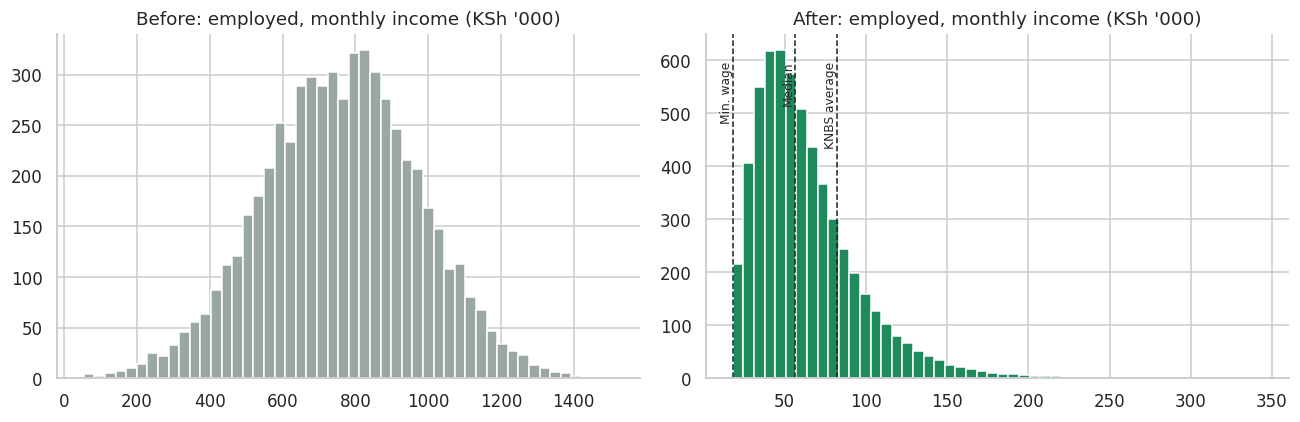

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
old = raw.loc[raw["Employment_Status"] == "Employed", "_old_monthly_kes"].dropna()
ax[0].hist(old / 1000, bins=50, color="#9AA8A1"); ax[0].set_title("Before: employed, monthly income (KSh '000)")
ax[1].hist(emp / 1000, bins=50, color="#1F8A5B")
for v, lab in [(MIN_WAGE_CITY / 1000, "Min. wage"), (np.exp(MU_EMP) / 1000, "Median"), (82.35, "KNBS average")]:
    ax[1].axvline(v, ls="--", color="#12261F", lw=1); ax[1].text(v, ax[1].get_ylim()[1] * .92, lab, rotation=90, va="top", ha="right", fontsize=8)
ax[1].set_title("After: employed, monthly income (KSh '000)")
plt.tight_layout(); plt.show()

## 6. Exploratory analysis on the calibrated data

> **What this cell does.** Draws three exploratory charts (risk class balance, income by risk class, risk mix by employment status) and a table of the Medium/High share by late-payment history.

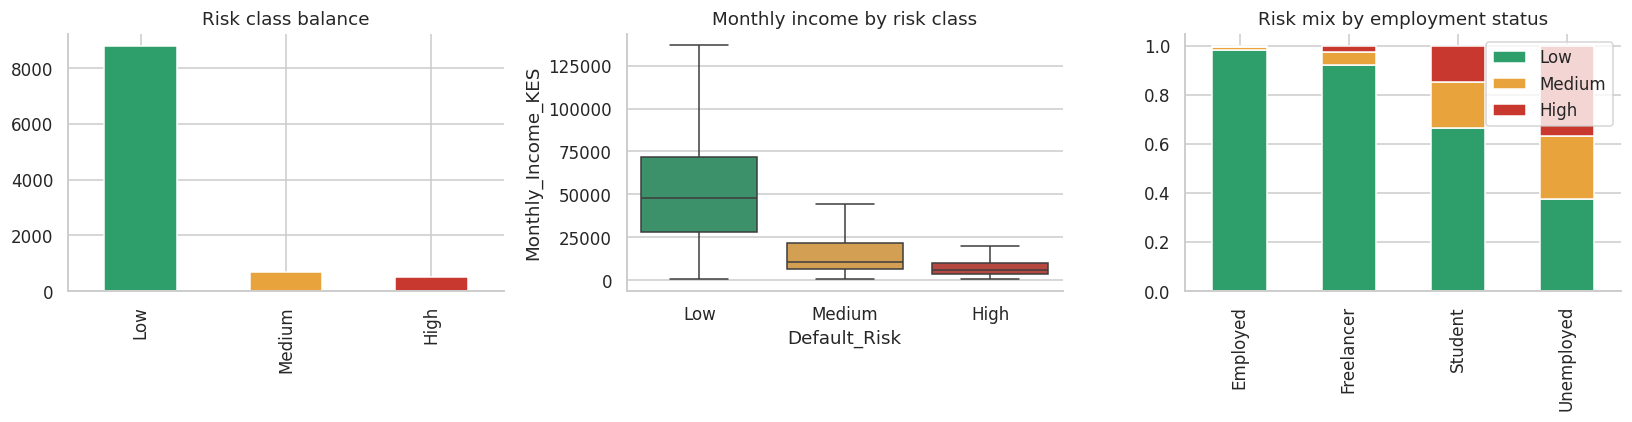

Late payment history and non-Low risk:


,share_non_low
Late_Payment_History,
No,0.054
Yes,0.319


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = ["Low", "Medium", "High"]
cal["Default_Risk"].value_counts().reindex(order).plot.bar(ax=ax[0], color=[PALETTE[o] for o in order]); ax[0].set_title("Risk class balance"); ax[0].set_xlabel("")
sns.boxplot(data=cal, x="Default_Risk", y="Monthly_Income_KES", order=order, palette=PALETTE, ax=ax[1], showfliers=False); ax[1].set_title("Monthly income by risk class")
mix = pd.crosstab(cal["Employment_Status"], cal["Default_Risk"], normalize="index")[order]
mix.plot.bar(stacked=True, ax=ax[2], color=[PALETTE[o] for o in order]); ax[2].set_title("Risk mix by employment status"); ax[2].set_xlabel(""); ax[2].legend(title="")
plt.tight_layout(); plt.show()

print("Late payment history and non-Low risk:")
display(cal.groupby("Late_Payment_History")["Default_Risk"].apply(lambda s: round((s != "Low").mean(), 3)).to_frame("share_non_low"))

## 7. Train/test split and leakage-safe imputation



> **What this cell does.** Splits the data 80/20, keeping the risk mix the same in both parts. Missing income and credit scores are filled with the training median of each employment group, and the counts are logged. It then builds the model inputs, labels (Low = 0, Medium = 1, High = 2) and class weights.

In [9]:
train_df, test_df = train_test_split(cal, test_size=0.20, stratify=cal["Default_Risk"], random_state=SEED)
IMPUTE_COLS = ["Monthly_Income_KES", "Credit_Score"]
medians = {c: train_df.groupby("Employment_Status")[c].median().to_dict() for c in IMPUTE_COLS}

def impute_group_median(df):
    df = df.copy()
    for c in IMPUTE_COLS:
        df[f"{c}_Imputed"] = df[c].isna()
        df[c] = df[c].fillna(df["Employment_Status"].map(medians[c]))
    return df

train_df, test_df = impute_group_median(train_df), impute_group_median(test_df)
cleaning_log = pd.DataFrame({
    "field": IMPUTE_COLS,
    "imputed_in_train": [int(train_df[f"{c}_Imputed"].sum()) for c in IMPUTE_COLS],
    "imputed_in_test": [int(test_df[f"{c}_Imputed"].sum()) for c in IMPUTE_COLS],
})
display(cleaning_log)

X_train, X_test = core.add_features(train_df)[core.FEATURES], core.add_features(test_df)[core.FEATURES]
y_train, y_test = train_df["Default_Risk"].map(core.CLASS_TO_INT).values, test_df["Default_Risk"].map(core.CLASS_TO_INT).values
sw_train = compute_sample_weight("balanced", y_train)
print(X_train.shape, X_test.shape, "| train class counts:", np.bincount(y_train), "| test:", np.bincount(y_test))

,field,imputed_in_train,imputed_in_test
0,Monthly_Income_KES,246,59
1,Credit_Score,231,67


(8000, 10) (2000, 10) | train class counts: [7041  542  417] | test: [1760  136  104]


## 8. Model comparison

Four candidates are tuned with stratified 5-fold cross-validation, scoring **macro F1** so the minority classes count as much as the majority. Imbalance is handled with class weights. The preprocessing sits inside the pipeline, so each fold is fitted on its own training portion only.

> **What this cell does.** Builds the preprocessing (fill and scale numbers, fill and one-hot encode categories) and defines four candidate models with their tuning grids. Each is tuned with 5-fold cross-validation on macro F1, scored on the test set, and collected into a results table.

In [10]:
def make_prep():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, core.NUM_COLS), ("cat", cat, core.CAT_COLS)])

CANDIDATES = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"),
                            {"model__C": [0.1, 1, 10]}, False),
    "Random Forest": (RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
                      {"model__n_estimators": [200], "model__max_depth": [None, 14], "model__min_samples_leaf": [1, 3]}, False),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"model__n_estimators": [150], "model__learning_rate": [0.1], "model__max_depth": [3, 4]}, True),
    "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", random_state=SEED, n_jobs=1),
                {"model__n_estimators": [150, 250], "model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 5]}, True),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
searches, rows = {}, []
for name, (est, grid, needs_sw) in CANDIDATES.items():
    pipe = Pipeline([("prep", make_prep()), ("model", est)])
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=1, refit=True)
    gs.fit(X_train, y_train, **({"model__sample_weight": sw_train} if needs_sw else {}))
    searches[name] = gs
    proba = gs.predict_proba(X_test); pred = proba.argmax(1)
    rows.append({
        "Model": name, "CV macro F1": gs.best_score_,
        "Test accuracy": accuracy_score(y_test, pred), "Test macro precision": precision_score(y_test, pred, average="macro"),
        "Test macro recall": recall_score(y_test, pred, average="macro"), "Test macro F1": f1_score(y_test, pred, average="macro"),
        "Test ROC AUC (OvR)": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
        "Best parameters": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
    })
    print(f"{name:20s} CV macro F1 = {gs.best_score_:.3f}")
comparison = pd.DataFrame(rows).sort_values("CV macro F1", ascending=False).reset_index(drop=True)
display(comparison.drop(columns="Best parameters").round(3))

Logistic Regression  CV macro F1 = 0.815
Random Forest        CV macro F1 = 0.865
Gradient Boosting    CV macro F1 = 0.856
XGBoost              CV macro F1 = 0.863


,Model,CV macro F1,Test accuracy,Test macro precision,Test macro recall,Test macro F1,Test ROC AUC (OvR)
0,Random Forest,0.865,0.958,0.851,0.889,0.868,0.987
1,XGBoost,0.863,0.954,0.835,0.885,0.857,0.987
2,Gradient Boosting,0.856,0.944,0.822,0.898,0.850,0.987
3,Logistic Regression,0.815,0.920,0.792,0.906,0.824,0.978


> **What this cell does.** Chooses the final model: the best cross-validated score, with ties within 0.005 going to XGBoost because it can explain individual customers. It prints the choice and saves the comparison table.

In [ ]:
TIE_TOL = 0.005
top_cv = comparison["CV macro F1"].max()
tied = comparison.loc[comparison["CV macro F1"] >= top_cv - TIE_TOL, "Model"].tolist()
BEST_NAME = "XGBoost" if "XGBoost" in tied else comparison.loc[0, "Model"]
best_row = comparison.loc[comparison["Model"] == BEST_NAME].iloc[0]
best_search = searches[BEST_NAME]; best_pipe = best_search.best_estimator_
NEEDS_SW = CANDIDATES[BEST_NAME][2]
SELECTION_RULE = f"Highest cross-validated macro F1; models within {TIE_TOL} of the best are tied and the one with exact customer-level explanations is preferred. Tied: {', '.join(tied)}."
print("Models within tolerance of the best CV score:", tied)
print("Selected model:", BEST_NAME, "| CV macro F1:", round(best_row["CV macro F1"], 3), "| parameters:", best_row["Best parameters"])
comparison.assign(**{"Best parameters": comparison["Best parameters"].astype(str)}).to_csv(APP / "reports" / "model_comparison.csv", index=False)

Models within tolerance of the best CV score: ['Random Forest', 'XGBoost']
Selected model: XGBoost | CV macro F1: 0.863 | parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 250}


## 9. probabilities

Class weights make the raw probabilities over-state risk. A small multinomial logistic model (vector scaling) is fitted on **out-of-fold** training predictions so the probabilities mean what they say. That matters for any pricing or limit decision.

> **What this cell does.** Calibrates the probabilities. It collects out-of-fold predictions on the training data, fits a small logistic model to correct them, and compares log loss, Brier score and calibration error before and after on the test set. The results are saved.

In [12]:
fit_params = {"model__sample_weight": sw_train} if NEEDS_SW else None
oof_raw = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method="predict_proba", params=fit_params)
calibrator = LogisticRegression(C=100, max_iter=5000).fit(np.log(np.clip(oof_raw, 1e-6, 1)), y_train)

raw_test = best_pipe.predict_proba(X_test)
cal_test = core.calibrate(calibrator, raw_test)
oof_cal = core.calibrate(calibrator, oof_raw)

def brier_multiclass(p, y): return float(np.mean(np.sum((p - np.eye(3)[y]) ** 2, axis=1)))
def ece(score, bad, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(score, edges) - 1, 0, bins - 1); total = 0
    for b in range(bins):
        m = idx == b
        if m.any(): total += m.mean() * abs(score[m].mean() - bad[m].mean())
    return float(total)

nonlow_test = (y_test > 0).astype(int)
calib_report = pd.DataFrame({
    "Metric": ["Log loss", "Brier score", "Expected calibration error (risk score)"],
    "Raw probabilities": [log_loss(y_test, raw_test), brier_multiclass(raw_test, y_test), ece(raw_test[:, 1:].sum(1), nonlow_test)],
    "Calibrated": [log_loss(y_test, cal_test), brier_multiclass(cal_test, y_test), ece(cal_test[:, 1:].sum(1), nonlow_test)],
}).round(4)
display(calib_report)
calib_report.to_csv(APP / "reports" / "calibration_metrics.csv", index=False)

,Metric,Raw probabilities,Calibrated
0,Log loss,0.1296,0.0990
1,Brier score,0.0716,0.0571
2,Expected calibration error (risk score),0.0251,0.0122


> **What this cell does.** Builds a table of predicted against observed risk by score band, saves it, and plots the calibration curve.

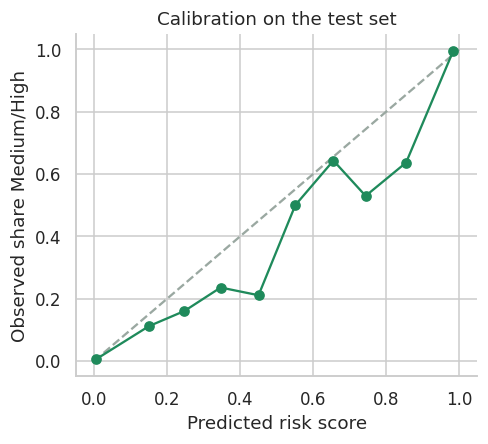

In [13]:
score_test = cal_test[:, 1:].sum(1)
bins = np.linspace(0, 1, 11); b = np.clip(np.digitize(score_test, bins) - 1, 0, 9)
reliability = pd.DataFrame({"bin": b, "predicted": score_test, "observed": nonlow_test}).groupby("bin").agg(
    predicted=("predicted", "mean"), observed=("observed", "mean"), customers=("observed", "size")).reset_index(drop=True)
reliability.to_csv(APP / "reports" / "reliability.csv", index=False)
plt.figure(figsize=(4.6, 4.2)); plt.plot([0, 1], [0, 1], "--", color="#9AA8A1")
plt.plot(reliability["predicted"], reliability["observed"], "o-", color="#1F8A5B")
plt.xlabel("Predicted risk score"); plt.ylabel("Observed share Medium/High"); plt.title("Calibration on the test set"); plt.tight_layout(); plt.show()

## 10. Decision cutoffs

The lender's decision is a tier (Low, Medium, High), not an argmax over probabilities. A customer is **High** if their calibrated P(High) is above one cutoff, otherwise **Medium** if their combined risk score P(Medium) + P(High) is above a second cutoff, otherwise **Low**. Both cutoffs are tuned on **out-of-fold training predictions** to maximise macro F1, so the test set stays untouched.

> **What this cell does.** Tunes the two tier cutoffs (High and Medium) on out-of-fold training predictions, then evaluates them on the test set against a plain argmax rule. It prints the classification report, saves the confusion matrix and per-class results, and plots the confusion matrix.

Tuned cutoffs: {'high': 0.56, 'medium': 0.42} | out-of-fold macro F1: 0.875


,Rule,Accuracy,Macro precision,Macro recall,Macro F1
0,argmax of calibrated probabilities,0.960,0.862,0.873,0.867
1,Tuned tier cutoffs (deployed),0.956,0.854,0.882,0.864


              precision    recall  f1-score   support

         Low      0.989     0.973     0.981      1760
      Medium      0.645     0.816     0.721       136
        High      0.927     0.856     0.890       104

    accuracy                          0.957      2000
   macro avg      0.854     0.882     0.864      2000
weighted avg      0.962     0.957     0.959      2000



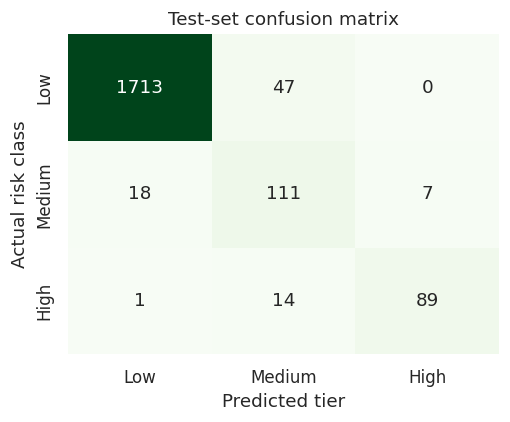

In [14]:
def tiers_int(p, th_high, th_med):
    s = p[:, 1] + p[:, 2]
    return np.where(p[:, 2] >= th_high, 2, np.where(s >= th_med, 1, 0))

grid = np.arange(0.10, 0.91, 0.02); best = (-1, None, None)
for th_h in grid:
    for th_m in grid:
        f = f1_score(y_train, tiers_int(oof_cal, th_h, th_m), average="macro")
        if f > best[0]: best = (f, th_h, th_m)
THRESHOLDS = {"high": round(float(best[1]), 2), "medium": round(float(best[2]), 2)}
print("Tuned cutoffs:", THRESHOLDS, "| out-of-fold macro F1:", round(best[0], 3))

pred_tier = tiers_int(cal_test, THRESHOLDS["high"], THRESHOLDS["medium"])
pred_argmax = cal_test.argmax(1)
decision_report = pd.DataFrame({
    "Rule": ["argmax of calibrated probabilities", "Tuned tier cutoffs (deployed)"],
    "Accuracy": [accuracy_score(y_test, pred_argmax), accuracy_score(y_test, pred_tier)],
    "Macro precision": [precision_score(y_test, pred_argmax, average="macro"), precision_score(y_test, pred_tier, average="macro")],
    "Macro recall": [recall_score(y_test, pred_argmax, average="macro"), recall_score(y_test, pred_tier, average="macro")],
    "Macro F1": [f1_score(y_test, pred_argmax, average="macro"), f1_score(y_test, pred_tier, average="macro")],
}).round(3)
display(decision_report)
print(classification_report(y_test, pred_tier, target_names=core.CLASSES, digits=3))
cm = confusion_matrix(y_test, pred_tier)
pd.DataFrame(cm, index=[f"Actual {c}" for c in core.CLASSES], columns=[f"Predicted {c}" for c in core.CLASSES]).to_csv(APP / "reports" / "confusion_matrix.csv")
pd.DataFrame(classification_report(y_test, pred_tier, target_names=core.CLASSES, output_dict=True)).T.to_csv(APP / "reports" / "per_class_report.csv")
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, xticklabels=core.CLASSES, yticklabels=core.CLASSES, ax=ax)
ax.set_xlabel("Predicted tier"); ax.set_ylabel("Actual risk class"); ax.set_title("Test-set confusion matrix"); plt.tight_layout(); plt.show()

## 11. Explainability

Two views: **permutation importance** (how much macro F1 drops when a feature is shuffled) and, for XGBoost, **exact TreeSHAP contributions** aggregated back to the original features. The deployed app uses the contributions to give each customer's top risk drivers.

> **What this cell does.** Measures which fields matter most using permutation importance and, for XGBoost, exact per-customer contributions (TreeSHAP). It saves the importance table and plots the drivers for the highest-scoring test customer.

,feature,permutation_importance,permutation_std,mean_abs_contribution,label
0,Debt_to_Income,0.4403,0.0084,5.4152,Debt relative to income
1,Late_Payment_History,0.1218,0.0112,1.9090,Late payment history
2,Employment_Status,0.0859,0.0072,0.5650,Employment status
3,Total_BNPL_Debt_KES,0.0783,0.0145,1.4213,Outstanding BNPL debt
4,Credit_Score,0.0163,0.0051,0.9866,Credit score
5,Monthly_Income_KES,0.0098,0.0083,1.0815,Monthly income
6,Total_BNPL_Active_Loans,0.0085,0.0069,0.8500,Active BNPL loans
7,Age,0.0006,0.0036,0.2170,Age
8,Shopping_Category_Most_Frequent,-0.0016,0.0030,0.0762,Most frequent purchase category
9,Average_Transaction_Value_KES,-0.0024,0.0021,0.3492,Average purchase value


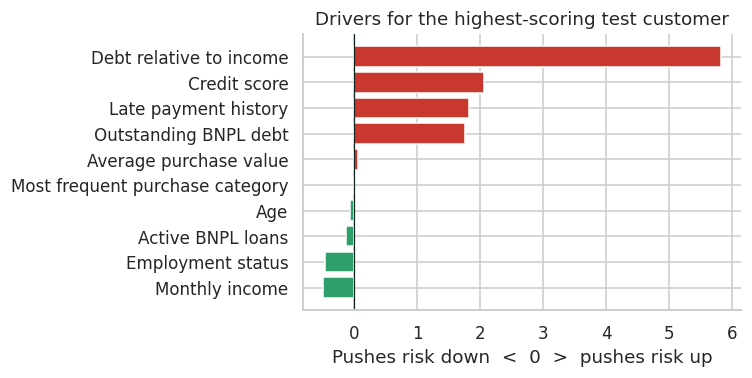

In [15]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({"feature": core.FEATURES, "permutation_importance": perm.importances_mean, "permutation_std": perm.importances_std})
art_tmp = core.Artifacts(best_pipe, calibrator, {"thresholds": THRESHOLDS, "model_name": BEST_NAME})
contrib_test = core.explain(art_tmp, test_df)
if contrib_test is not None:
    importance["mean_abs_contribution"] = contrib_test.abs().mean().reindex(core.FEATURES).values
importance["label"] = importance["feature"].map(core.FEATURE_LABELS)
importance = importance.sort_values("permutation_importance", ascending=False).reset_index(drop=True)
importance.to_csv(APP / "reports" / "feature_importance.csv", index=False)
display(importance.round(4))

if contrib_test is not None:
    sample = score = core.score_customers(art_tmp, test_df)
    i = sample["Risk_Score"].idxmax()
    row = contrib_test.loc[i].sort_values()
    plt.figure(figsize=(7, 3.6))
    plt.barh([core.FEATURE_LABELS[f] for f in row.index], row.values, color=["#2E9E6B" if v < 0 else "#C8382F" for v in row.values])
    plt.axvline(0, color="#12261F", lw=0.8); plt.title("Drivers for the highest-scoring test customer"); plt.xlabel("Pushes risk down  <  0  >  pushes risk up")
    plt.tight_layout(); plt.show()

## 12. Business impact

Lenders choose a cutoff, not an F1 score. For each risk-score cutoff the table below approves customers scoring *below* it and estimates profit using **illustrative** economics: exposure per customer, loss given default, margin on a performing loan, and the chance that a Medium customer defaults. These are placeholders; the app lets the user change them.

> **What this cell does.** Scores the test customers and saves the predictions. Using illustrative business assumptions (exposure, loss if default, margin), it calculates expected profit at each approval cutoff, prints the best cutoff against approving everyone, and plots the profit curve.

Assumptions: {'exposure': 2500.0, 'lgd': 0.7, 'margin': 0.12, 'medium_weight': 0.35}
Approve everyone: profit KSh 289,220, bad rate 7.6%
Best cutoff 0.50: approval 87.4%, profit KSh 507,282, bad rate 0.5%


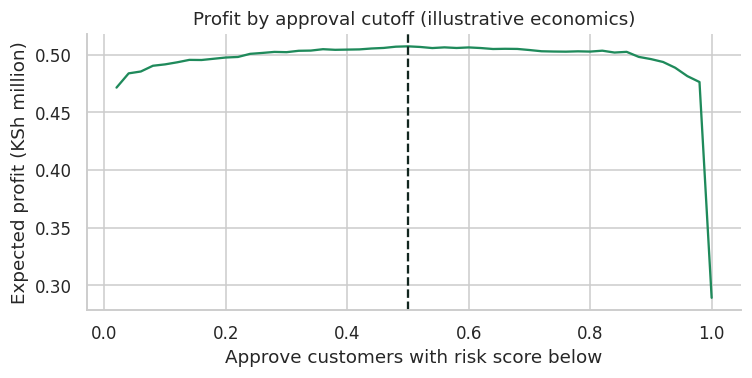

In [16]:
test_scored = core.score_customers(art_tmp, test_df)
test_out = pd.concat([test_df[["Customer_ID", "Employment_Status", "Age", "Monthly_Income_KES", "Total_BNPL_Debt_KES"]].reset_index(drop=True),
                      test_scored.reset_index(drop=True)], axis=1)
test_out.insert(3, "Actual_Risk", test_df["Default_Risk"].values)
test_out.to_csv(APP / "reports" / "test_predictions.csv", index=False)

ASSUME = {"exposure": float(round(cal["Total_BNPL_Debt_KES"].median(), -2)), "lgd": 0.70, "margin": 0.12, "medium_weight": 0.35}
cutoffs = np.round(np.arange(0.02, 1.0001, 0.02), 2)
curve = core.business_curve(test_scored["Risk_Score"].values / 100, test_out["Actual_Risk"].values, cutoffs, **ASSUME)
opt = curve.loc[curve["Expected_Profit"].idxmax()]
approve_all = core.business_curve(test_scored["Risk_Score"].values / 100, test_out["Actual_Risk"].values, np.array([1.01]), **ASSUME).iloc[0]
print(f"Assumptions: {ASSUME}")
print(f"Approve everyone: profit KSh {approve_all['Expected_Profit']:,.0f}, bad rate {approve_all['Bad_Rate']:.1%}")
print(f"Best cutoff {opt['Cutoff']:.2f}: approval {opt['Approval_Rate']:.1%}, profit KSh {opt['Expected_Profit']:,.0f}, bad rate {opt['Bad_Rate']:.1%}")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve["Cutoff"], curve["Expected_Profit"] / 1e6, color="#1F8A5B"); ax.axvline(opt["Cutoff"], ls="--", color="#12261F")
ax.set_xlabel("Approve customers with risk score below"); ax.set_ylabel("Expected profit (KSh million)"); ax.set_title("Profit by approval cutoff (illustrative economics)")
plt.tight_layout(); plt.show()

## 13. Fairness and monitoring check

The deployed rule flags a customer when the tier is Medium or High. The table compares how often each group is flagged, and the flag's recall and false-positive rate. Employment status and age are legitimate risk-related fields in this dataset but also sensitive; large gaps in the false-positive rate deserve a review before any real use.

> **What this cell does.** Runs a fairness check. For each employment status and age band it compares how often customers are flagged, how many risky customers are caught, and the false-alarm rate. The table is saved.

In [17]:
fx = test_out.copy()
fx["Age_Band"] = core.age_band(fx["Age"]).astype(str)
fx["flagged"] = fx["Risk_Tier"] != "Low"; fx["bad"] = fx["Actual_Risk"] != "Low"
def group_table(col):
    g = fx.groupby(col)
    t = pd.DataFrame({
        "customers": g.size(),
        "actual_non_low_rate": g["bad"].mean(),
        "flagged_rate": g["flagged"].mean(),
        "recall": g.apply(lambda d: (d["flagged"] & d["bad"]).sum() / max(d["bad"].sum(), 1)),
        "false_positive_rate": g.apply(lambda d: (d["flagged"] & ~d["bad"]).sum() / max((~d["bad"]).sum(), 1)),
    }).reset_index().rename(columns={col: "group"})
    t.insert(0, "dimension", col); return t
fairness = pd.concat([group_table("Employment_Status"), group_table("Age_Band")]).round(3)
fairness.to_csv(APP / "reports" / "fairness.csv", index=False)
display(fairness)

,dimension,group,customers,actual_non_low_rate,flagged_rate,recall,false_positive_rate
0,Employment_Status,Employed,1160,0.018,0.025,0.810,0.011
1,Employment_Status,Freelancer,290,0.055,0.083,0.812,0.040
2,Employment_Status,Student,433,0.312,0.333,0.933,0.060
3,Employment_Status,Unemployed,117,0.581,0.607,0.956,0.122
0,Age_Band,18-24,634,0.107,0.118,0.912,0.023
1,Age_Band,25-34,544,0.125,0.142,0.956,0.025
2,Age_Band,35-44,361,0.133,0.147,0.875,0.035
3,Age_Band,45-54,264,0.114,0.136,0.933,0.034
4,Age_Band,55+,197,0.132,0.137,0.923,0.018


## 14. Sensitivity of the assumptions

The employment-group assumptions (freelancer, student, unemployed) are not backed by official data. This check refits the best model under alternative assumptions and compares macro F1 on a held-out set built the same way. If scores barely move, the conclusions do not hinge on those guesses; the *levels* still matter for credibility, even when the *ranking* is what the model learns.

> **What this cell does.** Tests how much the results depend on the income assumptions. It rebuilds the data and refits the model under alternatives (all incomes up or down 25%, non-employed medians halved or doubled) and compares macro F1. The table is saved.

In [ ]:
import copy
def scenario(name, edit):
    t = copy.deepcopy(TARGETS); edit(t)
    d, _ = c_dataset(raw, t)
    tr, te = train_test_split(d, test_size=0.20, stratify=d["Default_Risk"], random_state=SEED)
    meds = {c: tr.groupby("Employment_Status")[c].median().to_dict() for c in IMPUTE_COLS}
    for df_ in (tr, te):
        for c in IMPUTE_COLS: df_[c] = df_[c].fillna(df_["Employment_Status"].map(meds[c]))
    Xa, Xb = core.add_features(tr)[core.FEATURES], core.add_features(te)[core.FEATURES]
    ya, yb = tr["Default_Risk"].map(core.CLASS_TO_INT).values, te["Default_Risk"].map(core.CLASS_TO_INT).values
    p = clone(best_pipe); p.fit(Xa, ya, **({"model__sample_weight": compute_sample_weight("balanced", ya)} if NEEDS_SW else {}))
    return {"Scenario": name, "Macro F1 (argmax)": round(f1_score(yb, p.predict(Xb), average="macro"), 3),
            "Employed median (KSh)": round(d.loc[d.Employment_Status == "Employed", "Monthly_Income_KES"].median())}

def scale_all(k):
    def f(t):
        for v in t.values(): v["median"] *= k; v["floor"] *= k; v["cap"] *= k
    return f
def scale_non_emp(k):
    def f(t):
        for s, v in t.items():
            if s != "Employed": v["median"] *= k
    return f
sens = pd.DataFrame([
    scenario("Baseline", lambda t: None),
    scenario("All incomes -25%", scale_all(0.75)),
    scenario("All incomes +25%", scale_all(1.25)),
    scenario("Non-employed medians x0.5", scale_non_emp(0.5)),
    scenario("Non-employed medians x2", scale_non_emp(2.0)),
])
display(sens); sens.to_csv(APP / "reports" / "sensitivity.csv", index=False)

,Scenario,Macro F1 (argmax),Employed median (KSh)
0,Baseline,0.857,56490
1,All incomes -25%,0.852,42360
2,All incomes +25%,0.854,70610
3,Non-employed medians x0.5,0.867,56490
4,Non-employed medians x2,0.855,56490


## 15. deployment package

> **What this cell does.** Saves everything the app needs: the full calibrated dataset, the model, the calibrator, a metadata file (metrics, cutoffs, assumptions, versions) and the cleaning log.

In [19]:
full = impute_group_median(cal.copy())
keep = ["Customer_ID", "Age", "Employment_Status", "Monthly_Income_KES", "Credit_Score", "Total_BNPL_Active_Loans", "Total_BNPL_Debt_KES",
        "Late_Payment_History", "Shopping_Category_Most_Frequent", "Average_Transaction_Value_KES", "Default_Risk",
        "Monthly_Income_KES_Imputed", "Credit_Score_Imputed"]
full[keep].to_csv(APP / "data" / "kenya_calibrated_dataset.csv", index=False)

joblib.dump(best_pipe, APP / "models" / "risk_model.joblib", compress=3)
joblib.dump(calibrator, APP / "models" / "calibrator.joblib", compress=3)

final = best_row
meta = {
    "model_name": BEST_NAME,
    "selection_rule": SELECTION_RULE,
    "best_params": {k: (v if v is None or isinstance(v, (int, float, str)) else str(v)) for k, v in final["Best parameters"].items()},
    "cv_macro_f1": float(final["CV macro F1"]),
    "thresholds": THRESHOLDS,
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test, pred_tier)),
        "macro_precision": float(precision_score(y_test, pred_tier, average="macro")),
        "macro_recall": float(recall_score(y_test, pred_tier, average="macro")),
        "macro_f1": float(f1_score(y_test, pred_tier, average="macro")),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, pred_tier)),
        "roc_auc_ovr": float(roc_auc_score(y_test, cal_test, multi_class="ovr", average="macro")),
    },
    "class_balance": cal["Default_Risk"].value_counts().to_dict(),
    "train_size": int(len(train_df)), "test_size": int(len(test_df)),
    "business_assumptions": ASSUME,
    "imputation_medians": medians,
    "calibration": {"fx_usd_kes": FX, "money_scale_factor": float(DEBT_SCALE), "employed_lognormal": {"mu": float(MU_EMP), "sigma": float(SIGMA_EMP)},
                    "targets": {k: {kk: vv for kk, vv in v.items()} for k, v in TARGETS.items()},
                    "benchmarks": {"min_wage_city": MIN_WAGE_CITY, "min_wage_other": MIN_WAGE_OTHER, "knbs_formal_avg_monthly": 82350, "est_formal_median_monthly": float(np.exp(MU_EMP))}},
    "versions": {"python": platform.python_version(), "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(APP / "models" / "meta.json").write_text(json.dumps(meta, indent=2, default=float))
cleaning_log.to_csv(APP / "reports" / "data_cleaning_log.csv", index=False)
print("Saved:", sorted(str(p.relative_to(APP)) for p in APP.rglob("*") if p.is_file() and p.suffix in {".csv", ".joblib", ".json"}))

Saved: ['data/kenya_calibrated_dataset.csv', 'models/calibrator.joblib', 'models/meta.json', 'models/risk_model.joblib', 'reports/calibration_metrics.csv', 'reports/confusion_matrix.csv', 'reports/data_cleaning_log.csv', 'reports/fairness.csv', 'reports/feature_importance.csv', 'reports/model_comparison.csv', 'reports/per_class_report.csv', 'reports/reliability.csv', 'reports/sensitivity.csv', 'reports/test_predictions.csv']


> **What this cell does.** Reloads the saved model and calibrator and checks that they reproduce the notebook's test-set scores exactly, so the deployed app behaves like this notebook.

In [ ]:
art = core.load_artifacts(APP)
check = core.score_customers(art, test_df)
assert np.allclose(check["Risk_Score"].values, test_scored["Risk_Score"].values), "Saved artifacts do not reproduce the notebook scores"
print("Artifacts reload and reproduce the notebook scores. Tier mix on the test set:", check["Risk_Tier"].value_counts().to_dict())

Artifacts reload and reproduce the notebook scores. Tier mix on the test set: {'Low': 1732, 'Medium': 172, 'High': 96}


## 16. Limitations and next steps

* **Synthetic source.** The raw dataset's income scale matches neither India nor Kenya, and the risk labels were generated on that original scale. 
* **Assumptions.** The freelancer, student and unemployed income distributions and the business-impact economics are placeholders. 
* **Labels, not outcomes.** `Default_Risk` is a risk class, not a recorded repayment outcome, so the model has not been validated against real defaults.

